# Generative Adversarial Networks (GAN)
Una GAN es un modelo de IA y DL que funciona mediante la competición de dos redes neuronales:
- Generador: crea datos a partir de ruido.
- Discriminador: actúa como un juez. Recibe datos reales (del entrenamiento) y falsos (del generador) y tiene que adivinar cuáles son reales y cuáles son falsos.

Ambas redes se entrenan a la vez: el generador aprende a crear resultados cada vez más realistas para engañar al discriminador, y el discriminador se vuelve más estricto y preciso para no dejarse engañar. Este bucle se detiene cuando el generador produce datos tan reales que el discriminador ya no puede distinguir lo real de lo falso.

In [13]:
from typing import Generator

import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


Vamos a normalizar los datos al rango [-1,1] ya que la función de salida es la tanh, que está en ese rango. Además, al no necesitar conjunto de test, usaremos ese conjunto como conjunto de validación.

In [14]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train = datasets.MNIST("../data", train=True, download=True, transform=transform)
val = datasets.MNIST("../data", train=False, download=True, transform=transform)

train_dataloader = DataLoader(train, batch_size=128, shuffle=True)
val_dataloader = DataLoader(val, batch_size=128, shuffle=True)

## Generador
Vamos a crear la clase Generator, que será la encargada de generar las imágenes falsas a partir de ruido.

In [15]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_dim=28*28):
        super(Generator, self).__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, img_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

## Discriminador
Y esta sera la clase Discriminator, que será la encargada de diferenciar las imágenes falsas de las reales que genera Generator.

In [16]:
class Discriminator(nn.Module):
    def __init__(self, img_dim=28*28):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

## Training loop
Ahora vamos a definir nuestro bucle de entrenamiento en una función auxiliar parametrizable. A diferencia de TensorFlow que automatiza todo el proceso con un model.fit(), con PyTorch tenemos más libertad para controlar el flujo del entrenamiento. A pesar de ser una función larga, su estructura es simple.

In [19]:
def learning_loop(train_dataloader, val_dataloader, generator, discriminator, epochs, loss_fn, lr, opt_generator, opt_discriminator, val_freq, device):
    train_loss_gen, train_loss_dis, val_loss_dis, val_loss_gen = [], [], [], [] # almacenamos los errores de cada epoca para ambas redes en train y val

    opt_gen = opt_generator(generator.parameters(), lr=lr) # creamos los optimizadores para cada red
    opt_dis = opt_discriminator(discriminator.parameters(), lr=lr)

    with tqdm(range(epochs), desc="epoch") as pbar:
        for epoch in pbar: # para cada epoca
            generator.train()
            discriminator.train()
            train_step_loss_gen, train_step_loss_dis = [], [] # almacenamos los errores del paso actual
            for real, _ in train_dataloader: # para cada batch
                real = real.reshape(-1, 28*28).to(device) # pasamos la imagen del formato (batch, 28, 28) a (batch, 28*28)
                batch_size = real.size(0) # obtenemos el tamaño del batch

                label_real = torch.ones(batch_size, 1, device=device) # creamos una lista de 1s para indicar imagenes reales
                label_fake = torch.zeros(batch_size, 1, device=device) # creamos una lista de 0s para indicar imagenes falsas

                opt_dis.zero_grad() # reseteamos los gradientes a 0
                noise = torch.randn(batch_size, generator.z_dim, device=device) # generamos ruido para el generator
                fake = generator(noise) # creamos la imagen
                loss_dis_real = loss_fn(discriminator(real), label_real) # evaluamos las imagenes reales (tiene que dar 1)
                loss_dis_fake = loss_fn(discriminator(fake.detach()), label_fake) # evaluamos las falsas (tiene que dar 0)
                loss_dis = (loss_dis_real + loss_dis_fake) / 2 # hacemos la media de los errores obtenidos

                loss_dis.backward() # calculamos los gradientes
                opt_dis.step() # ajustamos los parametros del modelo usando los gradientes calculados
                train_step_loss_dis.append(loss_dis.item()) # añadimos el error del paso actual

                opt_gen.zero_grad() # reseteamos los gradientes a 0
                output = discriminator(fake) # obtenemos la salida de la imagen falsa
                loss_gen = loss_fn(output, label_real) # medimos el error de que tanto ha fallado el generator para engañar al discriminator

                loss_gen.backward() # calculamos los gradientes
                opt_gen.step() # ajustamos los parametros del modelo usando los gradientes calculados
                train_step_loss_gen.append(loss_gen.item()) # añadimos el error del paso actual

            t_dis = torch.tensor(train_step_loss_dis).mean() # calculamos la media de errores de la epoca actual
            t_gen = torch.tensor(train_step_loss_gen).mean()

            train_loss_dis.append(t_dis)
            train_loss_gen.append(t_gen)

            pbar.set_postfix({"loss_dis": f"{t_dis}", "loss_gen": f"{t_gen}"})

            if epoch % val_freq == 0: # cada val_freq epocas evaluamos (es lo mismo que arriba pero sin modificar la red)
                generator.eval()
                discriminator.eval()
                val_step_loss_dis, val_step_loss_gen = [], []
                with torch.no_grad():
                    for real_val, _ in val_dataloader:
                        real_val = real_val.reshape(-1, 28*28).to(device)
                        batch_size_val = real_val.size(0)

                        label_real_val = torch.ones(batch_size_val, 1, device=device)
                        label_fake_val = torch.zeros(batch_size_val, 1, device=device)

                        noise_val = torch.randn(batch_size_val, generator.z_dim, device=device)
                        fake_val = generator(noise_val)
                        loss_dis_val_real = loss_fn(discriminator(real_val), label_real_val)
                        loss_dis_val_fake = loss_fn(discriminator(fake_val), label_fake_val)
                        loss_dis_val = (loss_dis_val_real + loss_dis_val_fake) / 2

                        output_val = discriminator(fake_val)
                        loss_gen_val = loss_fn(output_val, label_real_val)

                        val_step_loss_dis.append(loss_dis_val.item())
                        val_step_loss_gen.append(loss_gen_val.item())

                v_disc = torch.tensor(val_step_loss_dis).mean()
                v_gen = torch.tensor(val_step_loss_gen).mean()

                val_loss_dis.append(v_disc)
                val_loss_gen.append(v_gen)

    return generator, discriminator, train_loss_gen, train_loss_dis, val_loss_gen, val_loss_dis # devolvemos los modelos entrenados y los errores


Ya teniendo nuestro bucle definido, vamos a definir los parámetros a continuación y empezar el entrenamiento.

In [20]:
torch.manual_seed(42)

lr = 0.0002
epochs = 50
loss_fn = nn.BCELoss()
opt_generator = torch.optim.Adam
opt_discriminator = torch.optim.Adam
generator = Generator(z_dim=10).to(device)
discriminator = Discriminator().to(device)
val_freq = 1

gen, dis, train_loss_gen, train_loss_dis, val_loss_gen, val_loss_dis = learning_loop(
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    generator=generator,
    discriminator=discriminator,
    epochs=epochs,
    loss_fn=loss_fn,
    lr=lr,
    opt_generator=opt_generator,
    opt_discriminator=opt_discriminator,
    val_freq=val_freq,
    device=device
)

epoch: 100%|██████████| 50/50 [11:23<00:00, 13.67s/it, loss_dis=3.211294412612915, loss_gen=0.23481665551662445] 


## Evolución del entrenamiento

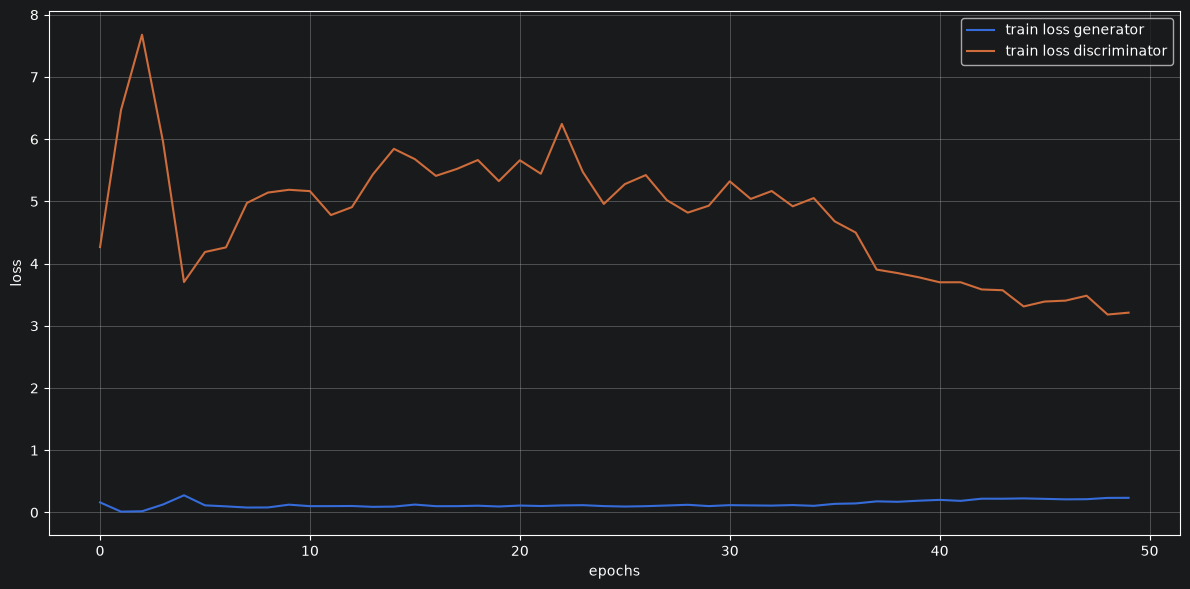

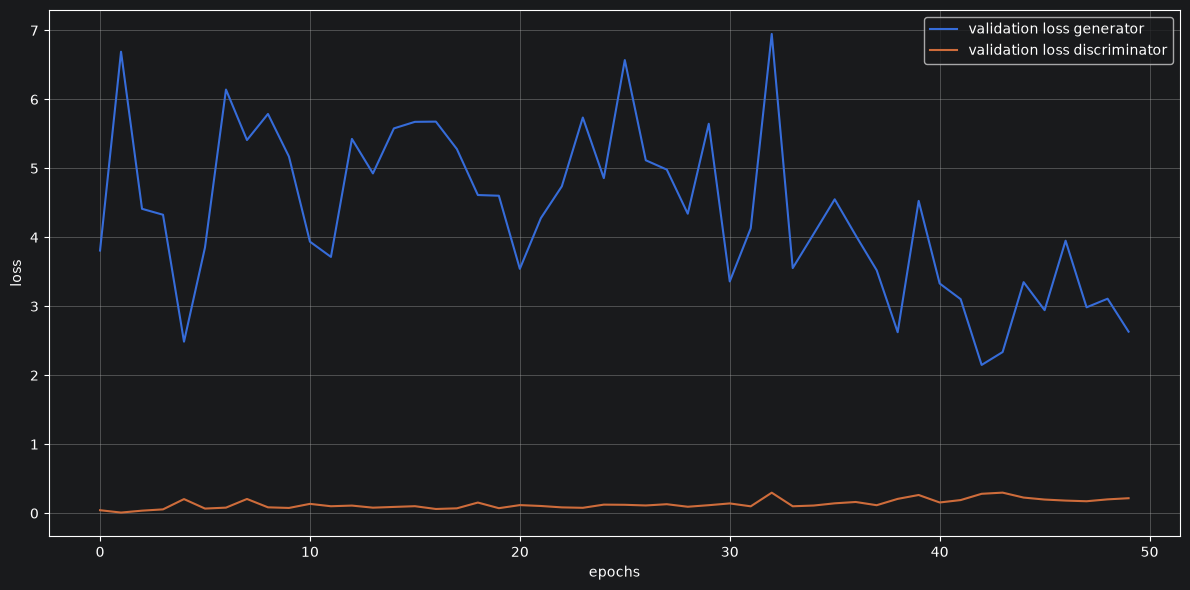

In [40]:
plt.figure(figsize=(12, 6))
plt.plot(range(len(train_loss_gen)), train_loss_gen, label="train loss generator")
plt.plot(range(len(train_loss_dis)), train_loss_dis, label="train loss discriminator")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(range(len(val_loss_gen)), val_loss_gen, label="validation loss generator")
plt.plot(range(len(val_loss_dis)), val_loss_dis, label="validation loss discriminator")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## Ejemplos del generador

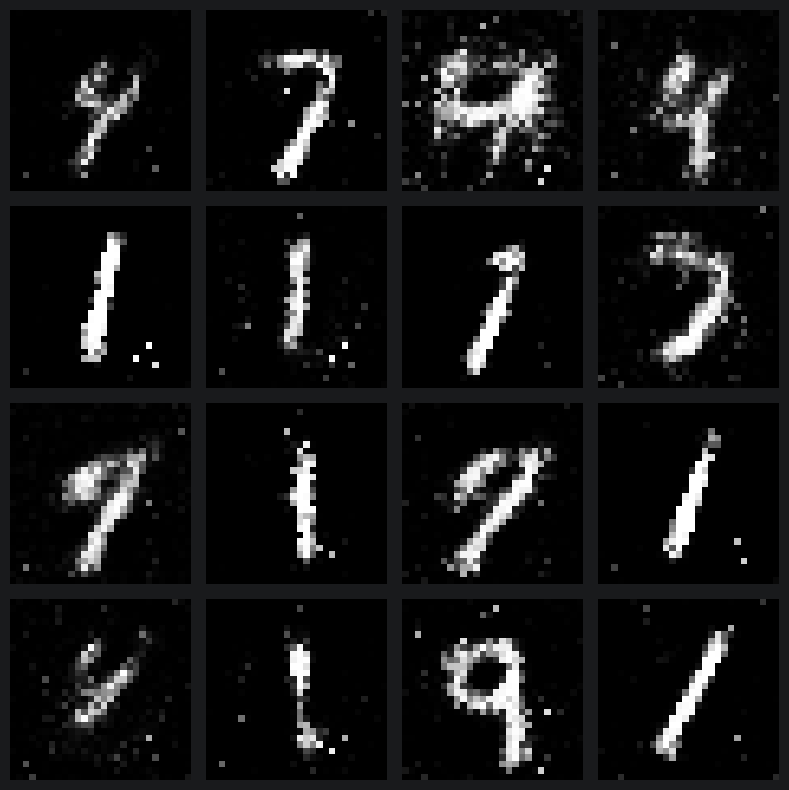

In [41]:
noise = torch.randn(16, generator.z_dim, device=device)

generator.eval()
with torch.no_grad():
    fakes = generator(noise).cpu()

fakes = fakes.reshape(16, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for img, ax in zip(fakes, axes.flatten()):
    ax.imshow((img + 1) / 2, cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()